In [ ]:
import numpy as np
import scipy.constants as const
import matplotlib.pyplot as plt

m_mu, unit, uncertainty = const.physical_constants['muon mass energy equivalent in MeV']
m_e, unit, uncertainty = const.physical_constants['electron mass energy equivalent in MeV']

#Constants for copper
Z = 29
A = 63.546          # g/mol
rho = 8.96          # g/cm^3
I = 322e-6          # mean ionization potential in MeV (322 eV)
K = 0.307075        # MeV cm^2 / mol

# density correction for Copper from https://journals.aps.org/pr/pdf/10.1103/PhysRev.88.851
C = 4.13          
x0 = 0.01
x1 = 3.0
a = 0.099
m = 3.40

### Muon energy loss data scrapped from Tab. I.38 https://www.sciencedirect.com/science/article/pii/S0092640X01908617

In [ ]:
momentum = np.array([
    4.704e1, 5.616e1, 6.802e1, 8.509e1, 1.003e2, 1.527e2,
    1.764e2, 2.218e2, 2.868e2, 3.577e2, 3.917e2, 4.945e2, 8.995e2,
    1.101e3, 1.502e3, 2.103e3, 3.104e3, 4.104e3, 8.105e3,
    1.011e4, 1.411e4, 2.011e4, 3.011e4, 4.011e4, 8.011e4,
    1.001e5, 1.401e5, 2.001e5, 3.001e5, 3.148e5, 4.001e5, 8.001e5,
    1.000e6, 1.400e6, 2.000e6, 3.000e6, 4.000e6, 8.000e6,
    1.000e7, 1.400e7, 2.000e7, 3.000e7, 4.000e7, 8.000e7, 1.000e8
])

# [MeV cm^2/g]
ionization_loss = np.array([
    5.283, 4.160, 3.277, 2.562, 2.198, 1.659,
    1.561, 1.464, 1.414, 1.403, 1.404, 1.419, 1.499,
    1.532, 1.585, 1.643, 1.709, 1.755, 1.860,
    1.891, 1.936, 1.981, 2.029, 2.061, 2.133,
    2.155, 2.187, 2.221, 2.259, 2.263, 2.285, 2.351,
    2.372, 2.404, 2.439, 2.479, 2.508, 2.579,
    2.602, 2.637, 2.676, 2.720, 2.752, 2.831, 2.856
])

# [MeV cm^2/g]
total_loss = np.array([
    5.283, 4.160, 3.277, 2.562, 2.198, 1.659,
    1.561, 1.464, 1.414, 1.403, 1.404, 1.419, 1.500,
    1.533, 1.587, 1.647, 1.716, 1.766, 1.886,
    1.927, 1.991, 2.068, 2.173, 2.267, 2.606,
    2.770, 3.095, 3.589, 4.405, 4.527, 5.237, 8.614,
    10.333, 13.766, 18.997, 27.703, 36.508, 71.970,
    89.830, 125.500, 179.321, 269.056, 359.160, 720.840, 902.257
])

## Bethe Bloch formula for muons

In [ ]:
# Bethe-Bloch mass stopping power [MeV cm^2/g] for muons in copper.
def mass_stopping_power(beta_gamma):
    beta_gamma = np.asarray(beta_gamma, dtype=float)
    if np.any(beta_gamma <= 0):
        raise ValueError("beta_gamma must be positive")

    beta_squared = beta_gamma**2 / (1 + beta_gamma**2)
    gamma = np.sqrt(1 + beta_gamma**2)
    x = np.log10(beta_gamma)

    # Piecewise Sternheimer density correction.
    density_correction = 2 * np.log(10) * x - C + np.where(x<x1, a*(x1 - x)**m, 0.0)

    t_max = 2*m_e*beta_squared * gamma**2/(1 + 2 * gamma * (m_e / m_mu) + (m_e / m_mu)**2)
    
    log_argument = 2*m_e*beta_squared*gamma**2*t_max/I**2
    result = (K * Z / A) / beta_squared * (
        0.5 * np.log(log_argument)
        - beta_squared
        - density_correction / 2
    )

    return result*(result > 0)  # Ensure non-negative stopping power

bg = np.logspace(-2, 5, 100)
dEdx = mass_stopping_power(bg)

plt.figure(figsize=(9, 6))
plt.loglog(bg, dEdx, 'r-', lw=2, label=r'Bethe-Bloch formula ($\mu^+$ na Cu)')
plt.loglog(momentum / m_mu, ionization_loss, 'bo', label='Experimental data (ionization loss)')

plt.xlabel(r'$\beta\gamma$', fontsize=12)
plt.ylabel(r'Mass stopping power [MeV cm$^2$/g]', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.xlim(1e-1, 1e5)
plt.legend(loc='upper right')

# Secondary x-axis: p = (beta*gamma) m_mu, displayed in GeV/c
ax = plt.gca()
momentum_axis = ax.secondary_xaxis(
    'top',
    functions=(lambda bg: bg * m_mu / 1000, lambda p_gev: p_gev * 1000 / m_mu),
)
momentum_axis.set_xlabel(r'Muon momentum $p$ [GeV/$c$]', fontsize=12);


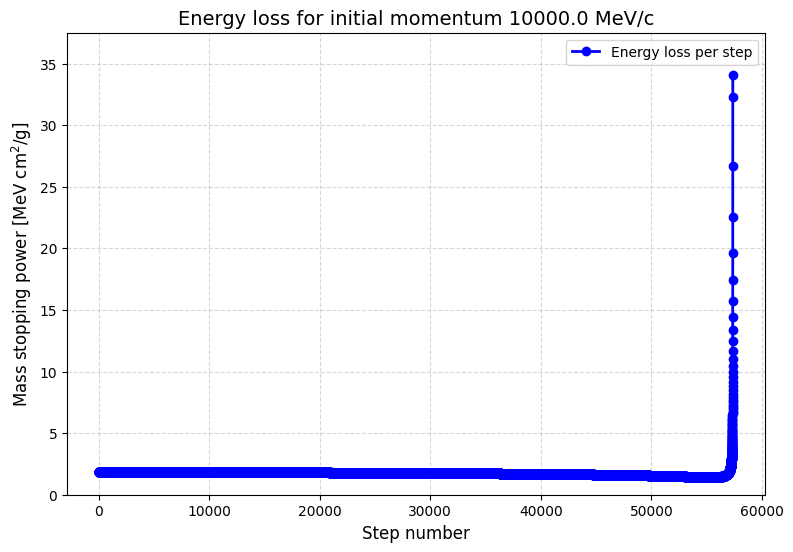

In [ ]:
initial_momentum = 10000.0  # MeV/c

momentum = initial_momentum
losses = []
while momentum > 1:
    beta_gamma = momentum / m_mu
    dEdx = mass_stopping_power(beta_gamma)
    if dEdx <1:
        break
    losses.append(dEdx)
  
    momentum -= dEdx*0.1  
    #print(f"Step {len(losses)}: p = {momentum:.2f} MeV/c, dE/dx = {dEdx:.4f} MeV cm^2/g")

plt.figure(figsize=(9, 6))
plt.plot(range(len(losses)), losses, 'bo-', lw=2, label='Energy loss per step')
plt.xlabel('Step number', fontsize=12)
plt.ylabel('Mass stopping power [MeV cm$^2$/g]', fontsize=12)
plt.title(f'Energy loss for initial momentum {initial_momentum} MeV/c', fontsize=14)
plt.ylim(0, max(losses) * 1.1)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(loc='upper right');
